In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("ecommerce_sales_analytics_5000.csv")
print("\n========== DATASET LOADED ==========")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())


print("\n========== FIRST 5 ROWS ==========")
print(df.head())


print("\n========== DATASET INFORMATION ==========")
print(df.info())


print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())


print("\n========== DUPLICATES ==========")
print("Number of duplicate rows:", df.duplicated().sum())


df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))


if 'order_date' in df.columns:
    df['order_date'] = pd.to_datetime(
        df['order_date'],
        errors='coerce'
    )


if 'order_date' in df.columns:
    print("\n========== INVALID DATES ==========")
    print(df['order_date'].isnull().sum())


print("\n========== NUMERICAL SUMMARY ==========")
print(df.describe())

if 'customer_rating' in df.columns:
    print("\n========== CUSTOMER RATING ==========")
    print("Minimum rating:",
          df['customer_rating'].min())
    print("Maximum rating:",
          df['customer_rating'].max())
    print("Average rating:",
          df['customer_rating'].mean())


if 'product_category' in df.columns:
    print("\n========== PRODUCT CATEGORIES ==========")
    print(df['product_category'].value_counts())


if 'order_date' in df.columns:
    df['year'] = df['order_date'].dt.year
    df['month'] = df['order_date'].dt.month
    df['day'] = df['order_date'].dt.day


if 'customer_id' in df.columns:
    customer_orders = df['customer_id'].value_counts()

    print("\n========== CUSTOMER ACTIVITY ==========")
    print(customer_orders.head(10))


if 'revenue' in df.columns:
    print("\n========== REVENUE ==========")
    print("Total revenue:", df['revenue'].sum())
    print("Average order revenue:",
          df['revenue'].mean())


df.to_csv(
    "ecommerce_cleaned_day1.csv",
    index=False
)




========== DATASET LOADED ==========
Rows: 5000
Columns: 12

========== COLUMN NAMES ==========
['order_id', 'order_date', 'customer_id', 'product_category', 'region', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'customer_rating', 'revenue']

========== FIRST 5 ROWS ==========
   order_id order_date  customer_id product_category region  quantity  \
0     10001   1/1/2022         1102           Beauty  South         7   
1     10002   1/2/2022         1435         Clothing  South         7   
2     10003   1/3/2022         1860           Beauty   East         3   
3     10004   1/4/2022         1270      Electronics   West         5   
4     10005   1/5/2022         1106         Clothing   West         5   

   unit_price  discount payment_method  delivery_days  customer_rating  \
0      373.65      0.28         Wallet             10              4.7   
1       47.74      0.09           Card              6              3.9   
2      311.28      0.31        


========== PRODUCT CATEGORY ANALYSIS ==========
product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64

========== CUSTOMER ANALYSIS ==========
Total unique customers: 989

Top 10 active customers:
customer_id
1663    14
1957    12
1098    12
1112    12
1928    12
1935    12
1669    12
1038    12
1276    11
1475    11
Name: count, dtype: int64

========== RATING ANALYSIS ==========
Average rating: 2.9739800000000005
Minimum rating: 1.0
Maximum rating: 5.0

========== QUANTITY BY CATEGORY ==========
product_category
Electronics    7109
Clothing       6171
Home           3949
Beauty         2995
Name: quantity, dtype: int64

========== REVENUE BY CATEGORY ==========
product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

========== MONTHLY REVENUE ==========
month_year
2022-01    35624.89
2022-02    29908.89
2022-03    30309.

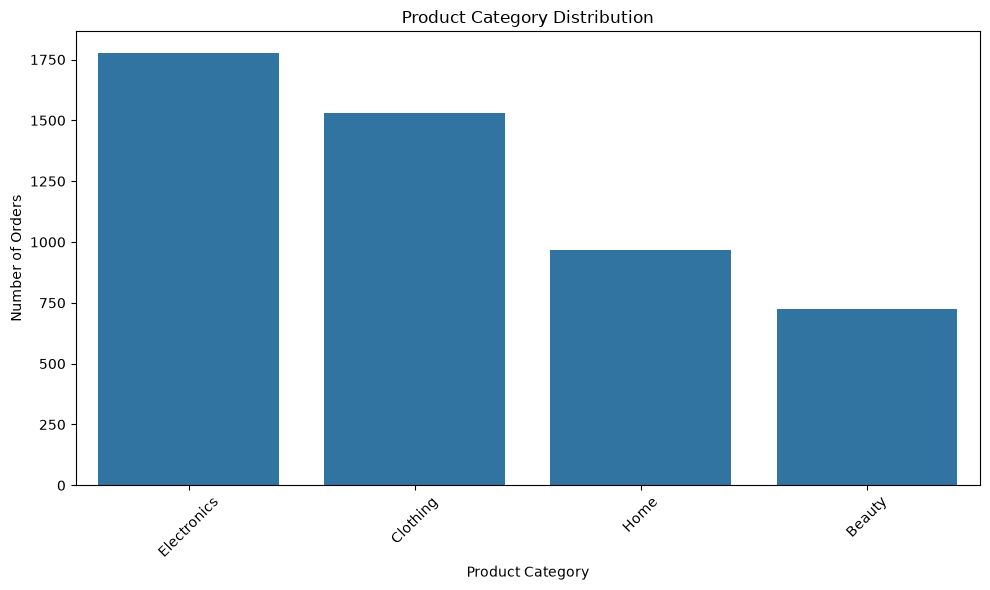

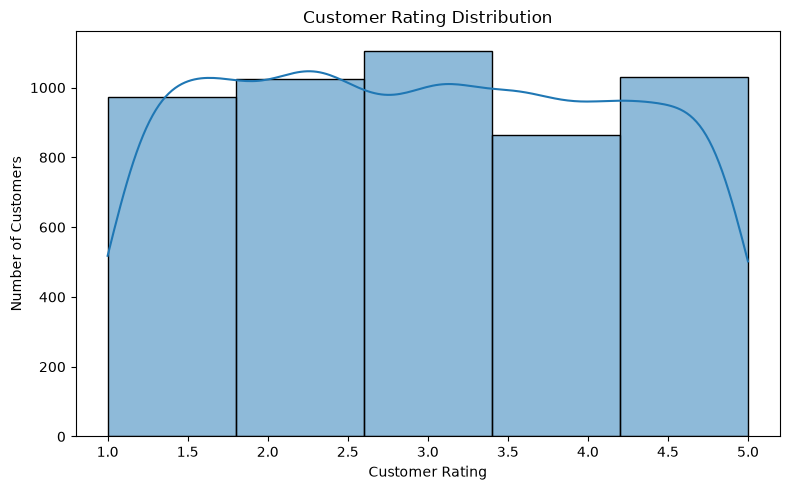

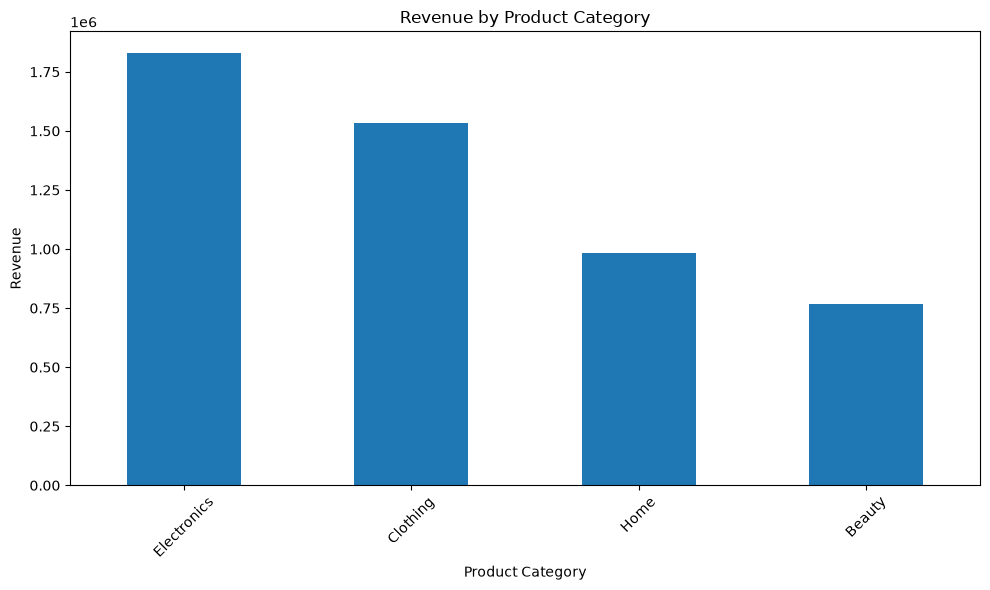

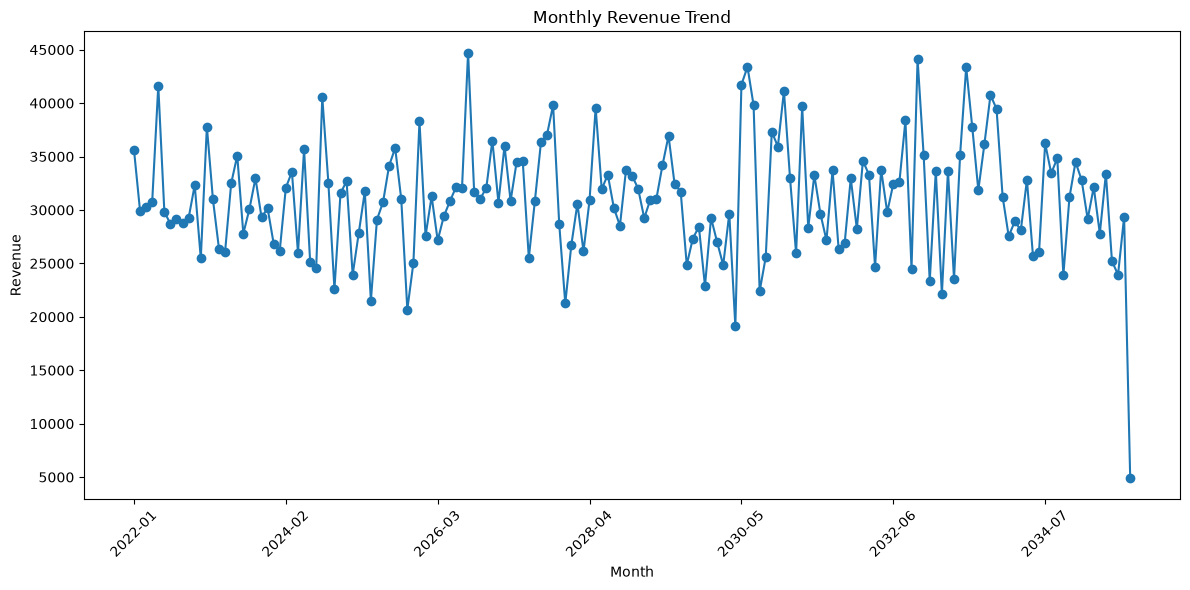


EDA COMPLETED


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("ecommerce_cleaned_day1.csv")

# Convert date
df['order_date'] = pd.to_datetime(df['order_date'])

# ==========================================
# 1. PRODUCT CATEGORY ANALYSIS
# ==========================================

print("\n========== PRODUCT CATEGORY ANALYSIS ==========")

category_count = df['product_category'].value_counts()

print(category_count)


# ==========================================
# 2. CUSTOMER ANALYSIS
# ==========================================

print("\n========== CUSTOMER ANALYSIS ==========")

print("Total unique customers:",
      df['customer_id'].nunique())

print("\nTop 10 active customers:")

print(
    df['customer_id']
    .value_counts()
    .head(10)
)


# ==========================================
# 3. RATING ANALYSIS
# ==========================================

print("\n========== RATING ANALYSIS ==========")

print("Average rating:",
      df['customer_rating'].mean())

print("Minimum rating:",
      df['customer_rating'].min())

print("Maximum rating:",
      df['customer_rating'].max())


# ==========================================
# 4. QUANTITY BY CATEGORY
# ==========================================

print("\n========== QUANTITY BY CATEGORY ==========")

quantity_by_category = (
    df.groupby('product_category')['quantity']
    .sum()
    .sort_values(ascending=False)
)

print(quantity_by_category)


# ==========================================
# 5. REVENUE BY CATEGORY
# ==========================================

print("\n========== REVENUE BY CATEGORY ==========")

revenue_by_category = (
    df.groupby('product_category')['revenue']
    .sum()
    .sort_values(ascending=False)
)

print(revenue_by_category)


# ==========================================
# 6. MONTHLY REVENUE
# ==========================================

df['month_year'] = (
    df['order_date']
    .dt.to_period('M')
    .astype(str)
)

monthly_revenue = (
    df.groupby('month_year')['revenue']
    .sum()
)

print("\n========== MONTHLY REVENUE ==========")

print(monthly_revenue)


# ==========================================
# 7. CATEGORY VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='product_category',
    order=df['product_category'].value_counts().index
)

plt.title("Product Category Distribution")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ==========================================
# 8. RATING VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='customer_rating',
    bins=5,
    kde=True
)

plt.title("Customer Rating Distribution")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


# ==========================================
# 9. REVENUE BY CATEGORY
# ==========================================

plt.figure(figsize=(10, 6))

revenue_by_category.plot(kind='bar')

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ==========================================
# 10. MONTHLY REVENUE TREND
# ==========================================

plt.figure(figsize=(12, 6))

monthly_revenue.plot(
    kind='line',
    marker='o'
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


print("\n========================================")
print("EDA COMPLETED")
print("========================================")

In [5]:
import pandas as pd

# ==========================================
# USER-PRODUCT ANALYSIS
# ==========================================

# Load cleaned dataset
df = pd.read_csv("ecommerce_cleaned_day1.csv")

print("\n========== DATASET ==========")
print(df.shape)
print(df.columns.tolist())


# ==========================================
# 1. UNIQUE CUSTOMERS
# ==========================================

print("\n========== CUSTOMERS ==========")

print("Number of unique customers:",
      df['customer_id'].nunique())


# ==========================================
# 2. PRODUCT INFORMATION
# ==========================================

print("\n========== PRODUCT INFORMATION ==========")

print("Number of product categories:",
      df['product_category'].nunique())

print("\nProduct categories:")

print(
    df['product_category']
    .unique()
)


# ==========================================
# 3. PURCHASES BY CUSTOMER
# ==========================================

customer_purchase_count = (
    df.groupby('customer_id')
      .size()
      .sort_values(ascending=False)
)

print("\n========== CUSTOMER PURCHASES ==========")

print(customer_purchase_count.head(10))


# ==========================================
# 4. CUSTOMER-CATEGORY PREFERENCES
# ==========================================

customer_category = pd.crosstab(
    df['customer_id'],
    df['product_category']
)

print("\n========== CUSTOMER-CATEGORY MATRIX ==========")

print(customer_category.head())


# ==========================================
# 5. RATING MATRIX
# ==========================================

rating_matrix = pd.pivot_table(
    df,
    index='customer_id',
    columns='product_category',
    values='customer_rating',
    aggfunc='mean',
    fill_value=0
)

print("\n========== CUSTOMER-CATEGORY RATING MATRIX ==========")

print(rating_matrix.head())


# ==========================================
# 6. CUSTOMER PREFERENCE
# ==========================================

customer_preference = (
    df.groupby(
        ['customer_id', 'product_category']
    )['quantity']
    .sum()
    .reset_index()
)

print("\n========== CUSTOMER PREFERENCES ==========")

print(customer_preference.head(20))


# ==========================================
# 7. FIND PREFERRED CATEGORY FOR EACH USER
# ==========================================

preferred_category = (
    customer_preference
    .sort_values(
        ['customer_id', 'quantity'],
        ascending=[True, False]
    )
    .drop_duplicates('customer_id')
)

print("\n========== PREFERRED CATEGORY ==========")

print(preferred_category.head(10))


# ==========================================
# 8. SAVE USER FEATURES
# ==========================================

user_features = df.groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    total_quantity=('quantity', 'sum'),
    total_spending=('revenue', 'sum'),
    average_rating=('customer_rating', 'mean')
).reset_index()

print("\n========== USER FEATURES ==========")

print(user_features.head(10))


user_features.to_csv(
    "user_features.csv",
    index=False
)

print("\nUser features saved successfully.")


print("\n==========================================")
print("USER-PRODUCT ANALYSIS COMPLETED")
print("==========================================")


========== DATASET ==========
(5000, 15)
['order_id', 'order_date', 'customer_id', 'product_category', 'region', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'customer_rating', 'revenue', 'year', 'month', 'day']

========== CUSTOMERS ==========
Number of unique customers: 989

========== PRODUCT INFORMATION ==========
Number of product categories: 4

Product categories:
<ArrowStringArray>
['Beauty', 'Clothing', 'Electronics', 'Home']
Length: 4, dtype: str

========== CUSTOMER PURCHASES ==========
customer_id
1663    14
1957    12
1928    12
1935    12
1112    12
1669    12
1038    12
1098    12
1726    11
1675    11
dtype: int64

========== CUSTOMER-CATEGORY MATRIX ==========
product_category  Beauty  Clothing  Electronics  Home
customer_id                                          
1000                   0         4            4     1
1001                   2         1            0     3
1002                   2         1            1     0
1003            

In [6]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# ==========================================
# COLLABORATIVE FILTERING
# ==========================================

# 1. Load cleaned dataset
df = pd.read_csv("ecommerce_cleaned_day1.csv")

print("\n========== DATASET LOADED ==========")
print("Rows:", len(df))


# ==========================================
# 2. CREATE USER-CATEGORY RATING MATRIX
# ==========================================

user_category_matrix = pd.pivot_table(
    df,
    index='customer_id',
    columns='product_category',
    values='customer_rating',
    aggfunc='mean',
    fill_value=0
)

print("\n========== USER-CATEGORY MATRIX ==========")

print(user_category_matrix.head())

print(
    "\nMatrix shape:",
    user_category_matrix.shape
)


# ==========================================
# 3. CALCULATE USER SIMILARITY
# ==========================================

user_similarity = cosine_similarity(
    user_category_matrix
)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_category_matrix.index,
    columns=user_category_matrix.index
)

print("\n========== USER SIMILARITY ==========")

print(user_similarity_df.head())


# ==========================================
# 4. FUNCTION TO FIND SIMILAR USERS
# ==========================================

def find_similar_users(customer_id, number_of_users=5):

    if customer_id not in user_similarity_df.index:
        print("Customer not found.")
        return None

    similarities = user_similarity_df.loc[customer_id]

    similarities = similarities.drop(
        customer_id
    )

    similar_users = (
        similarities
        .sort_values(ascending=False)
        .head(number_of_users)
    )

    return similar_users


# ==========================================
# 5. TEST WITH FIRST CUSTOMER
# ==========================================

customer_id = user_category_matrix.index[0]

print("\n========== SELECTED CUSTOMER ==========")
print("Customer ID:", customer_id)

similar_users = find_similar_users(
    customer_id,
    5
)

print("\n========== SIMILAR USERS ==========")
print(similar_users)


# ==========================================
# 6. FIND CATEGORIES ALREADY PURCHASED
# ==========================================

customer_data = df[
    df['customer_id'] == customer_id
]

purchased_categories = set(
    customer_data['product_category']
)

print("\n========== PURCHASED CATEGORIES ==========")
print(purchased_categories)


# ==========================================
# 7. FIND CATEGORIES LIKED BY SIMILAR USERS
# ==========================================

recommended_categories = {}

for similar_user, similarity_score in similar_users.items():

    similar_user_data = df[
        df['customer_id'] == similar_user
    ]

    for _, row in similar_user_data.iterrows():

        category = row['product_category']
        rating = row['customer_rating']

        # Don't recommend categories
        # already purchased
        if category not in purchased_categories:

            score = (
                similarity_score * rating
            )

            if category not in recommended_categories:
                recommended_categories[category] = 0

            recommended_categories[category] += score


# ==========================================
# 8. SORT RECOMMENDATIONS
# ==========================================

recommendations = sorted(
    recommended_categories.items(),
    key=lambda x: x[1],
    reverse=True
)

print("\n========== RECOMMENDED CATEGORIES ==========")

if len(recommendations) == 0:

    print(
        "No new category recommendations found."
    )

else:

    for category, score in recommendations:

        print(
            f"{category} -> Score: {score:.3f}"
        )


# ==========================================
# 9. SAVE RECOMMENDATIONS
# ==========================================

recommendation_df = pd.DataFrame(
    recommendations,
    columns=[
        'Recommended_Category',
        'Recommendation_Score'
    ]
)

recommendation_df.to_csv(
    "collaborative_recommendations.csv",
    index=False
)

print(
    "\nRecommendations saved to "
    "collaborative_recommendations.csv"
)


print("\n==========================================")
print("COLLABORATIVE FILTERING COMPLETED")
print("==========================================")


========== DATASET LOADED ==========
Rows: 5000

========== USER-CATEGORY MATRIX ==========
product_category  Beauty  Clothing  Electronics      Home
customer_id                                              
1000                 0.0     2.825        2.325  3.100000
1001                 1.4     4.200        0.000  3.000000
1002                 4.6     4.100        1.900  0.000000
1003                 0.0     1.300        0.000  4.700000
1004                 0.0     0.000        3.200  1.733333

Matrix shape: (989, 4)

========== USER SIMILARITY ==========
customer_id      1000      1001      1002      1003      1004      1005  \
customer_id                                                               
1000         1.000000  0.825290  0.517427  0.780099  0.734204  0.646447   
1001         0.825290  1.000000  0.686103  0.750032  0.267180  0.560968   
1002         0.517427  0.686103  1.000000  0.169504  0.259086  0.000000   
1003         0.780099  0.750032  0.169504  1.000000  0.459047  

In [7]:
import pandas as pd

# Load your cleaned dataset
df = pd.read_csv("ecommerce_cleaned_day1.csv")

print("\n========== ALL COLUMNS ==========")
for column in df.columns:
    print(column)

print("\n========== DATASET SHAPE ==========")
print(df.shape)

print("\n========== SAMPLE DATA ==========")
print(df.head(10).to_string())

print("\n========== UNIQUE VALUES ==========")

for column in df.columns:
    print("\n", column)
    print("Unique values:", df[column].nunique())

print("\n========== PRODUCT CATEGORY ==========")
print(df['product_category'].value_counts())

print("\n========== CUSTOMER ==========")
print("Unique customers:",
      df['customer_id'].nunique())

print("\n========== ORDER IDs ==========")
if 'order_id' in df.columns:
    print("Unique orders:",
          df['order_id'].nunique())


========== ALL COLUMNS ==========
order_id
order_date
customer_id
product_category
region
quantity
unit_price
discount
payment_method
delivery_days
customer_rating
revenue
year
month
day

========== DATASET SHAPE ==========
(5000, 15)

========== SAMPLE DATA ==========
   order_id  order_date  customer_id product_category region  quantity  unit_price  discount payment_method  delivery_days  customer_rating  revenue  year  month  day
0     10001  2022-01-01         1102           Beauty  South         7      373.65      0.28         Wallet             10              4.7  1883.20  2022      1    1
1     10002  2022-01-02         1435         Clothing  South         7       47.74      0.09           Card              6              3.9   304.10  2022      1    2
2     10003  2022-01-03         1860           Beauty   East         3      311.28      0.31            COD              6              2.5   644.35  2022      1    3
3     10004  2022-01-04         1270      Electronics   West 

In [8]:
import pandas as pd
import numpy as np

# ==========================================
# CREATE PRODUCT-LEVEL DATASET
# ==========================================

# Load cleaned dataset
df = pd.read_csv("ecommerce_cleaned_day1.csv")

print("\n========== ORIGINAL DATASET ==========")
print("Rows:", len(df))


# ==========================================
# 1. CREATE PRICE GROUPS
# ==========================================

# Divide prices into 5 groups within each category
df['price_group'] = (
    df.groupby('product_category')['unit_price']
      .transform(
          lambda x: pd.qcut(
              x.rank(method='first'),
              q=5,
              labels=False
          ) + 1
      )
)

print("\n========== PRICE GROUPS ==========")
print(df['price_group'].value_counts().sort_index())


# ==========================================
# 2. CREATE PRODUCT ID
# ==========================================

df['ProductID'] = (
    df['product_category']
    .str.upper()
    .str[:3]
    + "_P"
    + df['price_group'].astype(str)
)


# ==========================================
# 3. CREATE PRODUCT NAME
# ==========================================

product_names = {

    'Electronics': {
        1: 'Basic Electronics',
        2: 'Standard Electronics',
        3: 'Smart Electronics',
        4: 'Premium Electronics',
        5: 'Advanced Electronics'
    },

    'Clothing': {
        1: 'Basic Clothing',
        2: 'Casual Clothing',
        3: 'Fashion Clothing',
        4: 'Premium Clothing',
        5: 'Designer Clothing'
    },

    'Home': {
        1: 'Basic Home Product',
        2: 'Home Essential',
        3: 'Smart Home Product',
        4: 'Premium Home Product',
        5: 'Luxury Home Product'
    },

    'Beauty': {
        1: 'Basic Beauty Product',
        2: 'Beauty Essential',
        3: 'Premium Beauty Product',
        4: 'Advanced Beauty Product',
        5: 'Luxury Beauty Product'
    }
}


df['ProductName'] = df.apply(
    lambda row:
        product_names[row['product_category']]
        [int(row['price_group'])],
    axis=1
)


# ==========================================
# 4. CREATE BRAND
# ==========================================

brand_mapping = {
    'Electronics': 'TechBrand',
    'Clothing': 'FashionBrand',
    'Home': 'HomeBrand',
    'Beauty': 'BeautyBrand'
}

df['Brand'] = df['product_category'].map(
    brand_mapping
)


# ==========================================
# 5. CREATE PRODUCT DESCRIPTION
# ==========================================

description_mapping = {

    'Electronics':
        'Electronic product designed for modern everyday use.',

    'Clothing':
        'Fashion and clothing product designed for everyday wear.',

    'Home':
        'Home product designed to improve comfort and convenience.',

    'Beauty':
        'Beauty product designed for personal care and daily use.'
}

df['Description'] = df['product_category'].map(
    description_mapping
)


# ==========================================
# 6. RENAME COLUMNS
# ==========================================

df = df.rename(columns={
    'customer_id': 'UserID',
    'customer_rating': 'Rating',
    'order_date': 'PurchaseDate',
    'unit_price': 'Price',
    'product_category': 'Category'
})


# ==========================================
# 7. CREATE INTERACTION SCORE
# ==========================================

df['Interaction'] = df['Rating']


# ==========================================
# 8. SELECT FINAL COLUMNS
# ==========================================

recommendation_df = df[
    [
        'UserID',
        'ProductID',
        'ProductName',
        'Category',
        'Brand',
        'Rating',
        'PurchaseDate',
        'Price',
        'Description',
        'quantity',
        'Interaction'
    ]
].copy()


# ==========================================
# 9. REMOVE DUPLICATES
# ==========================================

recommendation_df = (
    recommendation_df
    .drop_duplicates()
)


# ==========================================
# 10. DISPLAY PRODUCT INFORMATION
# ==========================================

print("\n========== PRODUCT INFORMATION ==========")

print(
    recommendation_df[
        [
            'ProductID',
            'ProductName',
            'Category',
            'Brand',
            'Price'
        ]
    ].head(20)
)


# ==========================================
# 11. CHECK PRODUCTS
# ==========================================

print("\n========== PRODUCT STATISTICS ==========")

print(
    "Unique users:",
    recommendation_df['UserID'].nunique()
)

print(
    "Unique products:",
    recommendation_df['ProductID'].nunique()
)

print(
    "Unique categories:",
    recommendation_df['Category'].nunique()
)


# ==========================================
# 12. PRODUCT PURCHASE COUNT
# ==========================================

product_purchase_count = (
    recommendation_df
    .groupby('ProductID')
    .size()
    .sort_values(ascending=False)
)

print("\n========== MOST PURCHASED PRODUCTS ==========")

print(
    product_purchase_count.head(10)
)


# ==========================================
# 13. CHECK MISSING VALUES
# ==========================================

print("\n========== MISSING VALUES ==========")

print(
    recommendation_df.isnull().sum()
)


# ==========================================
# 14. SAVE FINAL DATASET
# ==========================================

recommendation_df.to_csv(
    "recommendation_dataset.csv",
    index=False
)


print("\n==========================================")
print("PRODUCT DATASET CREATED SUCCESSFULLY")
print("==========================================")

print(
    "\nSaved as: recommendation_dataset.csv"
)


========== ORIGINAL DATASET ==========
Rows: 5000

========== PRICE GROUPS ==========
price_group
1    1002
2     999
3     999
4     999
5    1001
Name: count, dtype: int64

========== PRODUCT INFORMATION ==========
   ProductID              ProductName     Category         Brand   Price
0     BEA_P4  Advanced Beauty Product       Beauty   BeautyBrand  373.65
1     CLO_P1           Basic Clothing     Clothing  FashionBrand   47.74
2     BEA_P3   Premium Beauty Product       Beauty   BeautyBrand  311.28
3     ELE_P5     Advanced Electronics  Electronics     TechBrand  524.47
4     CLO_P2          Casual Clothing     Clothing  FashionBrand  139.87
5     ELE_P3        Smart Electronics  Electronics     TechBrand  264.44
6     CLO_P5        Designer Clothing     Clothing  FashionBrand  564.60
7     BEA_P3   Premium Beauty Product       Beauty   BeautyBrand  265.71
8     CLO_P2          Casual Clothing     Clothing  FashionBrand  224.65
9     CLO_P3         Fashion Clothing     Clothing  

In [9]:
import pandas as pd

# ==========================================
# USER-PRODUCT INTERACTION MATRIX
# ==========================================

# Load recommendation dataset
df = pd.read_csv("recommendation_dataset.csv")

print("\n========== DATASET LOADED ==========")

print("Rows:", len(df))
print("Users:", df['UserID'].nunique())
print("Products:", df['ProductID'].nunique())


# ==========================================
# 1. CREATE USER-PRODUCT RATING MATRIX
# ==========================================

user_product_matrix = pd.pivot_table(
    df,
    index='UserID',
    columns='ProductID',
    values='Rating',
    aggfunc='mean',
    fill_value=0
)


print("\n========== USER-PRODUCT MATRIX ==========")

print(user_product_matrix.head(10))


# ==========================================
# 2. MATRIX SIZE
# ==========================================

print("\n========== MATRIX INFORMATION ==========")

print(
    "Number of users:",
    user_product_matrix.shape[0]
)

print(
    "Number of products:",
    user_product_matrix.shape[1]
)


# ==========================================
# 3. CHECK PRODUCTS
# ==========================================

print("\n========== PRODUCTS ==========")

print(
    user_product_matrix.columns.tolist()
)


# ==========================================
# 4. CHECK ONE USER
# ==========================================

first_user = user_product_matrix.index[0]

print("\n========== FIRST USER ==========")

print("User ID:", first_user)

print(
    user_product_matrix.loc[first_user]
)


# ==========================================
# 5. CREATE PURCHASE MATRIX
# ==========================================

purchase_matrix = pd.pivot_table(
    df,
    index='UserID',
    columns='ProductID',
    values='quantity',
    aggfunc='sum',
    fill_value=0
)


print("\n========== PURCHASE MATRIX ==========")

print(purchase_matrix.head())


# ==========================================
# 6. SAVE MATRICES
# ==========================================

user_product_matrix.to_csv(
    "user_product_rating_matrix.csv"
)

purchase_matrix.to_csv(
    "user_product_purchase_matrix.csv"
)


print("\n==========================================")
print("USER-PRODUCT MATRIX CREATED SUCCESSFULLY")
print("==========================================")

print("\nFiles saved:")
print("1. user_product_rating_matrix.csv")
print("2. user_product_purchase_matrix.csv")


========== DATASET LOADED ==========
Rows: 5000
Users: 989
Products: 20

========== USER-PRODUCT MATRIX ==========
ProductID  BEA_P1    BEA_P2  BEA_P3  BEA_P4  BEA_P5  CLO_P1  CLO_P2  CLO_P3  \
UserID                                                                        
1000          0.0  0.000000    0.00     0.0     0.0     0.0     3.1    1.65   
1001          1.2  0.000000    1.60     0.0     0.0     4.2     0.0    0.00   
1002          4.6  0.000000    0.00     0.0     0.0     0.0     4.1    0.00   
1003          0.0  0.000000    0.00     0.0     0.0     0.0     0.0    0.00   
1004          0.0  0.000000    0.00     0.0     0.0     0.0     0.0    0.00   
1005          0.0  0.000000    0.00     0.0     0.0     0.0     0.0    0.00   
1006          0.0  0.000000    2.65     0.0     0.0     2.8     0.0    1.20   
1007          0.0  2.233333    0.00     0.0     0.0     0.0     0.0    0.00   
1008          0.0  0.000000    0.00     0.0     0.0     0.0     2.1    0.00   
1009          0

In [10]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# ==========================================
# COLLABORATIVE FILTERING
# ==========================================

# Load user-product rating matrix
matrix = pd.read_csv(
    "user_product_rating_matrix.csv",
    index_col=0
)

print("\n========== MATRIX LOADED ==========")
print("Users:", matrix.shape[0])
print("Products:", matrix.shape[1])


# ==========================================
# 1. CALCULATE USER SIMILARITY
# ==========================================

similarity = cosine_similarity(matrix)

similarity_df = pd.DataFrame(
    similarity,
    index=matrix.index,
    columns=matrix.index
)

print("\n========== USER SIMILARITY ==========")

print(similarity_df.iloc[:5, :5])


# ==========================================
# 2. FUNCTION TO FIND SIMILAR USERS
# ==========================================

def find_similar_users(user_id, number_of_users=5):

    if user_id not in similarity_df.index:
        print("User ID not found.")
        return None

    scores = similarity_df.loc[user_id]

    # Remove the same user
    scores = scores.drop(user_id)

    # Get most similar users
    similar_users = (
        scores
        .sort_values(ascending=False)
        .head(number_of_users)
    )

    return similar_users


# ==========================================
# 3. SELECT A USER
# ==========================================

user_id = matrix.index[0]

print("\n========== SELECTED USER ==========")
print("User ID:", user_id)


# ==========================================
# 4. FIND SIMILAR USERS
# ==========================================

similar_users = find_similar_users(
    user_id,
    5
)

print("\n========== TOP 5 SIMILAR USERS ==========")

print(similar_users)


# ==========================================
# 5. FIND PRODUCTS ALREADY PURCHASED
# ==========================================

user_products = matrix.loc[user_id]

purchased_products = user_products[
    user_products > 0
].index.tolist()

print("\n========== USER'S PURCHASED PRODUCTS ==========")

print(purchased_products)


# ==========================================
# 6. GENERATE PRODUCT SCORES
# ==========================================

product_scores = {}

for similar_user, similarity_score in similar_users.items():

    # Products rated by similar user
    similar_user_ratings = matrix.loc[
        similar_user
    ]

    for product, rating in similar_user_ratings.items():

        # Ignore products already purchased
        if product not in purchased_products:

            score = (
                similarity_score * rating
            )

            if product not in product_scores:
                product_scores[product] = 0

            product_scores[product] += score


# ==========================================
# 7. SORT PRODUCTS
# ==========================================

recommendations = sorted(
    product_scores.items(),
    key=lambda x: x[1],
    reverse=True
)


# ==========================================
# 8. DISPLAY RECOMMENDATIONS
# ==========================================

print("\n========== RECOMMENDED PRODUCTS ==========")

if len(recommendations) == 0:

    print("No new products found.")

else:

    for product, score in recommendations[:10]:

        print(
            f"{product} -> Score: {score:.3f}"
        )


# ==========================================
# 9. SAVE RECOMMENDATIONS
# ==========================================

recommendation_df = pd.DataFrame(
    recommendations,
    columns=[
        "ProductID",
        "CollaborativeScore"
    ]
)

recommendation_df.to_csv(
    "collaborative_recommendations.csv",
    index=False
)

print("\nRecommendations saved to:")
print("collaborative_recommendations.csv")


print("\n==========================================")
print("COLLABORATIVE FILTERING COMPLETED")
print("==========================================")


========== MATRIX LOADED ==========
Users: 989
Products: 20

========== USER SIMILARITY ==========
UserID      1000      1001      1002      1003      1004
UserID                                                  
1000    1.000000  0.255427  0.354271  0.165507  0.230486
1001    0.255427  1.000000  0.115979  0.365621  0.064695
1002    0.354271  0.115979  1.000000  0.000000  0.000000
1003    0.165507  0.365621  0.000000  1.000000  0.000000
1004    0.230486  0.064695  0.000000  0.000000  1.000000

========== SELECTED USER ==========
User ID: 1000

========== TOP 5 SIMILAR USERS ==========
UserID
1806    0.792032
1448    0.789942
1825    0.786816
1047    0.780693
1113    0.778125
Name: 1000, dtype: float64

========== USER'S PURCHASED PRODUCTS ==========
['CLO_P2', 'CLO_P3', 'CLO_P4', 'ELE_P1', 'ELE_P4', 'ELE_P5', 'HOM_P5']

========== RECOMMENDED PRODUCTS ==========
CLO_P1 -> Score: 2.412
BEA_P4 -> Score: 2.203
BEA_P2 -> Score: 0.871
BEA_P1 -> Score: 0.000
BEA_P3 -> Score: 0.000
BEA_P5 ->

In [11]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ==========================================
# CONTENT-BASED FILTERING
# ==========================================

# Load recommendation dataset
df = pd.read_csv("recommendation_dataset.csv")

print("\n========== DATASET LOADED ==========")

print("Rows:", len(df))
print("Products:", df['ProductID'].nunique())


# ==========================================
# 1. CREATE UNIQUE PRODUCT DATA
# ==========================================

product_data = (
    df[
        [
            'ProductID',
            'ProductName',
            'Category',
            'Brand',
            'Description'
        ]
    ]
    .drop_duplicates('ProductID')
    .reset_index(drop=True)
)

print("\n========== PRODUCT DATA ==========")

print(product_data)


# ==========================================
# 2. CREATE PRODUCT CONTENT
# ==========================================

product_data['content'] = (
    product_data['ProductName'].fillna('') + " " +
    product_data['Category'].fillna('') + " " +
    product_data['Brand'].fillna('') + " " +
    product_data['Description'].fillna('')
)

print("\n========== PRODUCT CONTENT ==========")

print(
    product_data[
        ['ProductID', 'content']
    ].head()
)


# ==========================================
# 3. TF-IDF
# ==========================================

tfidf = TfidfVectorizer(
    stop_words='english'
)

tfidf_matrix = tfidf.fit_transform(
    product_data['content']
)

print("\n========== TF-IDF ==========")

print("TF-IDF matrix shape:",
      tfidf_matrix.shape)


# ==========================================
# 4. COSINE SIMILARITY
# ==========================================

product_similarity = cosine_similarity(
    tfidf_matrix
)

similarity_df = pd.DataFrame(
    product_similarity,
    index=product_data['ProductID'],
    columns=product_data['ProductID']
)

print("\n========== PRODUCT SIMILARITY ==========")

print(
    similarity_df.iloc[:5, :5]
)


# ==========================================
# 5. FUNCTION TO FIND SIMILAR PRODUCTS
# ==========================================

def get_similar_products(
    product_id,
    number_of_products=5
):

    if product_id not in similarity_df.index:
        print("Product ID not found.")
        return None

    scores = similarity_df.loc[
        product_id
    ]

    # Remove the same product
    scores = scores.drop(product_id)

    similar_products = (
        scores
        .sort_values(ascending=False)
        .head(number_of_products)
    )

    return similar_products


# ==========================================
# 6. TEST PRODUCT
# ==========================================

test_product = product_data[
    'ProductID'
].iloc[0]

print("\n========== TEST PRODUCT ==========")

print("Product:", test_product)


# ==========================================
# 7. FIND SIMILAR PRODUCTS
# ==========================================

similar_products = get_similar_products(
    test_product,
    5
)

print("\n========== SIMILAR PRODUCTS ==========")

print(similar_products)


# ==========================================
# 8. DISPLAY PRODUCT NAMES
# ==========================================

print("\n========== PRODUCT RECOMMENDATIONS ==========")

for product_id, score in similar_products.items():

    product_name = product_data.loc[
        product_data['ProductID'] == product_id,
        'ProductName'
    ].iloc[0]

    print(
        f"{product_id} | "
        f"{product_name} | "
        f"Similarity: {score:.3f}"
    )


# ==========================================
# 9. SAVE SIMILARITY MATRIX
# ==========================================

similarity_df.to_csv(
    "content_product_similarity.csv"
)

print("\nSimilarity matrix saved to:")
print("content_product_similarity.csv")


print("\n==========================================")
print("CONTENT-BASED FILTERING COMPLETED")
print("==========================================")


========== DATASET LOADED ==========
Rows: 5000
Products: 20

========== PRODUCT DATA ==========
   ProductID              ProductName     Category         Brand  \
0     BEA_P4  Advanced Beauty Product       Beauty   BeautyBrand   
1     CLO_P1           Basic Clothing     Clothing  FashionBrand   
2     BEA_P3   Premium Beauty Product       Beauty   BeautyBrand   
3     ELE_P5     Advanced Electronics  Electronics     TechBrand   
4     CLO_P2          Casual Clothing     Clothing  FashionBrand   
5     ELE_P3        Smart Electronics  Electronics     TechBrand   
6     CLO_P5        Designer Clothing     Clothing  FashionBrand   
7     CLO_P3         Fashion Clothing     Clothing  FashionBrand   
8     ELE_P4      Premium Electronics  Electronics     TechBrand   
9     BEA_P5    Luxury Beauty Product       Beauty   BeautyBrand   
10    HOM_P4     Premium Home Product         Home     HomeBrand   
11    HOM_P1       Basic Home Product         Home     HomeBrand   
12    HOM_P2      

In [12]:
import pandas as pd
import numpy as np

# ==========================================
# HYBRID RECOMMENDATION SYSTEM
# ==========================================

# Load recommendation dataset
df = pd.read_csv("recommendation_dataset.csv")

# Load collaborative filtering results
cf = pd.read_csv(
    "collaborative_recommendations.csv"
)

# Load content similarity matrix
content_similarity = pd.read_csv(
    "content_product_similarity.csv",
    index_col=0
)

print("\n========== FILES LOADED ==========")

print("Dataset rows:", len(df))
print("Collaborative recommendations:", len(cf))
print("Content products:", len(content_similarity))


# ==========================================
# 1. SELECT USER
# ==========================================

user_id = 1000

print("\n========== SELECTED USER ==========")
print("User ID:", user_id)


# ==========================================
# 2. FIND USER'S PURCHASED PRODUCTS
# ==========================================

user_data = df[
    df['UserID'] == user_id
]

purchased_products = set(
    user_data['ProductID']
)

print("\n========== PURCHASED PRODUCTS ==========")

print(purchased_products)


# ==========================================
# 3. NORMALIZE COLLABORATIVE SCORE
# ==========================================

if len(cf) > 0:

    max_cf = cf['CollaborativeScore'].max()

    if max_cf > 0:
        cf['CF_Score'] = (
            cf['CollaborativeScore'] /
            max_cf
        )
    else:
        cf['CF_Score'] = 0

else:

    cf['CF_Score'] = 0


# ==========================================
# 4. CREATE CONTENT SCORE
# ==========================================

content_scores = {}

for product in content_similarity.columns:

    if product in purchased_products:
        continue

    # Find similarity with products
    # already purchased by user

    similarities = []

    for purchased_product in purchased_products:

        if purchased_product in content_similarity.index:

            score = content_similarity.loc[
                purchased_product,
                product
            ]

            similarities.append(score)

    if len(similarities) > 0:

        content_scores[product] = max(
            similarities
        )

    else:

        content_scores[product] = 0


# Convert content scores to DataFrame

content_df = pd.DataFrame(
    list(content_scores.items()),
    columns=[
        'ProductID',
        'ContentScore'
    ]
)


# ==========================================
# 5. MERGE CF + CONTENT SCORES
# ==========================================

hybrid = pd.merge(
    cf[
        [
            'ProductID',
            'CF_Score'
        ]
    ],
    content_df,
    on='ProductID',
    how='outer'
)

hybrid = hybrid.fillna(0)


# ==========================================
# 6. CALCULATE HYBRID SCORE
# ==========================================

# Collaborative Filtering weight
cf_weight = 0.6

# Content-Based Filtering weight
content_weight = 0.4

hybrid['HybridScore'] = (
    cf_weight * hybrid['CF_Score']
    +
    content_weight * hybrid['ContentScore']
)


# ==========================================
# 7. REMOVE ALREADY PURCHASED PRODUCTS
# ==========================================

hybrid = hybrid[
    ~hybrid['ProductID']
    .isin(purchased_products)
]


# ==========================================
# 8. SORT RECOMMENDATIONS
# ==========================================

hybrid = hybrid.sort_values(
    'HybridScore',
    ascending=False
)


# ==========================================
# 9. ADD PRODUCT INFORMATION
# ==========================================

product_info = (
    df[
        [
            'ProductID',
            'ProductName',
            'Category',
            'Brand',
            'Price',
            'Rating'
        ]
    ]
    .drop_duplicates('ProductID')
)

hybrid = pd.merge(
    hybrid,
    product_info,
    on='ProductID',
    how='left'
)


# ==========================================
# 10. DISPLAY TOP 10
# ==========================================

print("\n========== TOP HYBRID RECOMMENDATIONS ==========")

print(
    hybrid[
        [
            'ProductID',
            'ProductName',
            'Category',
            'CF_Score',
            'ContentScore',
            'HybridScore'
        ]
    ].head(10).to_string(index=False)
)


# ==========================================
# 11. SAVE RESULTS
# ==========================================

hybrid.to_csv(
    "hybrid_recommendations.csv",
    index=False
)

print("\nHybrid recommendations saved to:")
print("hybrid_recommendations.csv")


print("\n==========================================")
print("HYBRID RECOMMENDATION COMPLETED")
print("==========================================")


========== FILES LOADED ==========
Dataset rows: 5000
Collaborative recommendations: 13
Content products: 20

========== SELECTED USER ==========
User ID: 1000

========== PURCHASED PRODUCTS ==========
{'CLO_P2', 'CLO_P4', 'ELE_P1', 'HOM_P5', 'ELE_P4', 'ELE_P5', 'CLO_P3'}

========== TOP HYBRID RECOMMENDATIONS ==========
ProductID             ProductName    Category  CF_Score  ContentScore  HybridScore
   CLO_P1          Basic Clothing    Clothing  1.000000      0.929511     0.971804
   BEA_P4 Advanced Beauty Product      Beauty  0.913314      0.220674     0.636258
   HOM_P1      Basic Home Product        Home  0.000000      0.906831     0.362733
   HOM_P4    Premium Home Product        Home  0.000000      0.906831     0.362733
   CLO_P5       Designer Clothing    Clothing  0.000000      0.896870     0.358748
   HOM_P3      Smart Home Product        Home  0.000000      0.891047     0.356419
   HOM_P2          Home Essential        Home  0.000000      0.882721     0.353088
   ELE_P3   

In [13]:
import pandas as pd
import numpy as np

# ==========================================
# DYNAMIC ADAPTATION
# ==========================================

# Load recommendation dataset
df = pd.read_csv("recommendation_dataset.csv")

# Convert date
df['PurchaseDate'] = pd.to_datetime(
    df['PurchaseDate']
)

# ==========================================
# 1. SELECT USER
# ==========================================

user_id = 1000

user_data = df[
    df['UserID'] == user_id
].copy()

print("\n========== USER ==========")
print("User ID:", user_id)


# ==========================================
# 2. FIND MOST RECENT PURCHASE
# ==========================================

latest_date = user_data[
    'PurchaseDate'
].max()

print("\nLatest purchase date:")
print(latest_date)


# ==========================================
# 3. CALCULATE DAYS SINCE PURCHASE
# ==========================================

user_data['DaysAgo'] = (
    latest_date - user_data['PurchaseDate']
).dt.days


# ==========================================
# 4. CALCULATE RECENCY WEIGHT
# ==========================================

# More recent purchases get higher weight

user_data['RecencyWeight'] = np.exp(
    -0.05 * user_data['DaysAgo']
)


# ==========================================
# 5. CALCULATE WEIGHTED RATING
# ==========================================

user_data['WeightedRating'] = (
    user_data['Rating']
    *
    user_data['RecencyWeight']
)


# ==========================================
# 6. DISPLAY RECENT ACTIVITY
# ==========================================

recent_activity = user_data[
    [
        'ProductID',
        'ProductName',
        'Category',
        'PurchaseDate',
        'Rating',
        'DaysAgo',
        'RecencyWeight',
        'WeightedRating'
    ]
].sort_values(
    'PurchaseDate',
    ascending=False
)

print("\n========== RECENT USER ACTIVITY ==========")

print(
    recent_activity.head(10).to_string(
        index=False
    )
)


# ==========================================
# 7. CALCULATE PRODUCT INTEREST
# ==========================================

product_interest = (
    user_data
    .groupby('ProductID')
    .agg(
        WeightedRating=(
            'WeightedRating',
            'sum'
        ),
        AverageRating=(
            'Rating',
            'mean'
        ),
        PurchaseCount=(
            'ProductID',
            'count'
        )
    )
    .reset_index()
)


# ==========================================
# 8. SORT BY CURRENT INTEREST
# ==========================================

product_interest = (
    product_interest
    .sort_values(
        'WeightedRating',
        ascending=False
    )
)


print("\n========== CURRENT USER INTEREST ==========")

print(
    product_interest.head(10).to_string(
        index=False
    )
)


# ==========================================
# 9. CATEGORY INTEREST
# ==========================================

category_interest = (
    user_data
    .groupby('Category')
    .agg(
        RecentInterest=(
            'WeightedRating',
            'sum'
        ),
        AverageRating=(
            'Rating',
            'mean'
        ),
        Purchases=(
            'ProductID',
            'count'
        )
    )
    .reset_index()
)


category_interest = (
    category_interest
    .sort_values(
        'RecentInterest',
        ascending=False
    )
)


print("\n========== CURRENT CATEGORY INTEREST ==========")

print(
    category_interest.to_string(
        index=False
    )
)


# ==========================================
# 10. SAVE DYNAMIC FEATURES
# ==========================================

product_interest.to_csv(
    "dynamic_product_interest.csv",
    index=False
)

category_interest.to_csv(
    "dynamic_category_interest.csv",
    index=False
)


print("\n==========================================")
print("DYNAMIC ADAPTATION COMPLETED")
print("==========================================")

print("\nFiles saved:")
print("dynamic_product_interest.csv")
print("dynamic_category_interest.csv")


========== USER ==========
User ID: 1000

Latest purchase date:
2035-07-06 00:00:00

========== RECENT USER ACTIVITY ==========
ProductID          ProductName    Category PurchaseDate  Rating  DaysAgo  RecencyWeight  WeightedRating
   ELE_P5 Advanced Electronics Electronics   2035-07-06     4.0        0   1.000000e+00    4.000000e+00
   ELE_P5 Advanced Electronics Electronics   2034-05-09     1.0      423   6.526370e-10    6.526370e-10
   CLO_P3     Fashion Clothing    Clothing   2033-08-05     1.2      700   6.305117e-16    7.566140e-16
   ELE_P4  Premium Electronics Electronics   2029-10-10     1.5     2095   3.218496e-46    4.827745e-46
   CLO_P3     Fashion Clothing    Clothing   2029-07-23     2.1     2174   6.197119e-48    1.301395e-47
   ELE_P1    Basic Electronics Electronics   2026-05-05     2.8     3349   1.894039e-73    5.303310e-73
   CLO_P2      Casual Clothing    Clothing   2025-09-19     3.1     3577   2.120469e-78    6.573454e-78
   HOM_P5  Luxury Home Product        H

In [14]:
import pandas as pd
import numpy as np

# ==========================================
# IMPROVED DYNAMIC ADAPTATION
# ==========================================

df = pd.read_csv("recommendation_dataset.csv")

df['PurchaseDate'] = pd.to_datetime(
    df['PurchaseDate']
)

# ==========================================
# 1. SELECT USER
# ==========================================

user_id = 1000

user_data = df[
    df['UserID'] == user_id
].copy()

print("\n========== USER ==========")
print("User ID:", user_id)


# ==========================================
# 2. FIND DATE RANGE
# ==========================================

latest_date = user_data['PurchaseDate'].max()
earliest_date = user_data['PurchaseDate'].min()

total_days = (
    latest_date - earliest_date
).days

print("\nLatest purchase:")
print(latest_date)

print("\nEarliest purchase:")
print(earliest_date)

print("\nTotal time span:",
      total_days,
      "days")


# ==========================================
# 3. CALCULATE RECENCY SCORE
# ==========================================

if total_days > 0:

    user_data['RecencyScore'] = (
        (
            user_data['PurchaseDate']
            - earliest_date
        ).dt.days
        /
        total_days
    )

else:

    user_data['RecencyScore'] = 1.0


# ==========================================
# 4. CALCULATE DYNAMIC RATING
# ==========================================

user_data['DynamicScore'] = (
    user_data['Rating']
    *
    user_data['RecencyScore']
)


# ==========================================
# 5. DISPLAY ACTIVITY
# ==========================================

activity = user_data[
    [
        'ProductID',
        'ProductName',
        'Category',
        'PurchaseDate',
        'Rating',
        'RecencyScore',
        'DynamicScore'
    ]
].sort_values(
    'PurchaseDate',
    ascending=False
)

print("\n========== DYNAMIC USER ACTIVITY ==========")

print(
    activity.to_string(index=False)
)


# ==========================================
# 6. PRODUCT INTEREST
# ==========================================

product_interest = (
    user_data
    .groupby('ProductID')
    .agg(
        DynamicScore=(
            'DynamicScore',
            'sum'
        ),
        AverageRating=(
            'Rating',
            'mean'
        ),
        PurchaseCount=(
            'ProductID',
            'count'
        )
    )
    .reset_index()
)


product_interest = product_interest.sort_values(
    'DynamicScore',
    ascending=False
)


print("\n========== DYNAMIC PRODUCT INTEREST ==========")

print(
    product_interest.to_string(
        index=False
    )
)


# ==========================================
# 7. CATEGORY INTEREST
# ==========================================

category_interest = (
    user_data
    .groupby('Category')
    .agg(
        DynamicInterest=(
            'DynamicScore',
            'sum'
        ),
        AverageRating=(
            'Rating',
            'mean'
        ),
        Purchases=(
            'ProductID',
            'count'
        )
    )
    .reset_index()
)


category_interest = category_interest.sort_values(
    'DynamicInterest',
    ascending=False
)


print("\n========== DYNAMIC CATEGORY INTEREST ==========")

print(
    category_interest.to_string(
        index=False
    )
)


# ==========================================
# 8. SAVE RESULTS
# ==========================================

activity.to_csv(
    "dynamic_user_activity.csv",
    index=False
)

product_interest.to_csv(
    "dynamic_product_interest_v2.csv",
    index=False
)

category_interest.to_csv(
    "dynamic_category_interest_v2.csv",
    index=False
)


print("\n==========================================")
print("IMPROVED DYNAMIC ADAPTATION COMPLETED")
print("==========================================")

print("\nFiles saved:")
print("dynamic_user_activity.csv")
print("dynamic_product_interest_v2.csv")
print("dynamic_category_interest_v2.csv")


========== USER ==========
User ID: 1000

Latest purchase:
2035-07-06 00:00:00

Earliest purchase:
2024-06-16 00:00:00

Total time span: 4037 days

========== DYNAMIC USER ACTIVITY ==========
ProductID          ProductName    Category PurchaseDate  Rating  RecencyScore  DynamicScore
   ELE_P5 Advanced Electronics Electronics   2035-07-06     4.0      1.000000      4.000000
   ELE_P5 Advanced Electronics Electronics   2034-05-09     1.0      0.895219      0.895219
   CLO_P3     Fashion Clothing    Clothing   2033-08-05     1.2      0.826604      0.991925
   ELE_P4  Premium Electronics Electronics   2029-10-10     1.5      0.481050      0.721575
   CLO_P3     Fashion Clothing    Clothing   2029-07-23     2.1      0.461481      0.969111
   ELE_P1    Basic Electronics Electronics   2026-05-05     2.8      0.170424      0.477186
   CLO_P2      Casual Clothing    Clothing   2025-09-19     3.1      0.113946      0.353233
   HOM_P5  Luxury Home Product        Home   2024-11-15     3.1      0.

In [15]:
import pandas as pd

# ==========================================
# COLD START RECOMMENDATION
# ==========================================

df = pd.read_csv("recommendation_dataset.csv")

print("\n========== DATASET LOADED ==========")
print("Rows:", len(df))


# ==========================================
# 1. CALCULATE PRODUCT STATISTICS
# ==========================================

product_stats = (
    df.groupby(
        [
            'ProductID',
            'ProductName',
            'Category',
            'Brand'
        ]
    )
    .agg(
        AverageRating=('Rating', 'mean'),
        PurchaseCount=('ProductID', 'count'),
        TotalQuantity=('quantity', 'sum')
    )
    .reset_index()
)


# ==========================================
# 2. NORMALIZE RATING
# ==========================================

max_rating = product_stats[
    'AverageRating'
].max()

min_rating = product_stats[
    'AverageRating'
].min()

if max_rating > min_rating:

    product_stats['RatingScore'] = (
        (
            product_stats['AverageRating']
            - min_rating
        )
        /
        (
            max_rating
            - min_rating
        )
    )

else:

    product_stats['RatingScore'] = 1.0


# ==========================================
# 3. NORMALIZE POPULARITY
# ==========================================

max_purchase = product_stats[
    'PurchaseCount'
].max()

min_purchase = product_stats[
    'PurchaseCount'
].min()

if max_purchase > min_purchase:

    product_stats['PopularityScore'] = (
        (
            product_stats['PurchaseCount']
            - min_purchase
        )
        /
        (
            max_purchase
            - min_purchase
        )
    )

else:

    product_stats['PopularityScore'] = 1.0


# ==========================================
# 4. NORMALIZE QUANTITY
# ==========================================

max_quantity = product_stats[
    'TotalQuantity'
].max()

min_quantity = product_stats[
    'TotalQuantity'
].min()

if max_quantity > min_quantity:

    product_stats['QuantityScore'] = (
        (
            product_stats['TotalQuantity']
            - min_quantity
        )
        /
        (
            max_quantity
            - min_quantity
        )
    )

else:

    product_stats['QuantityScore'] = 1.0


# ==========================================
# 5. COLD START SCORE
# ==========================================

product_stats['ColdStartScore'] = (
    0.50 * product_stats['RatingScore']
    +
    0.30 * product_stats['PopularityScore']
    +
    0.20 * product_stats['QuantityScore']
)


# ==========================================
# 6. RANK PRODUCTS
# ==========================================

cold_start_products = (
    product_stats
    .sort_values(
        'ColdStartScore',
        ascending=False
    )
)


# ==========================================
# 7. DISPLAY TOP PRODUCTS
# ==========================================

print("\n========== COLD START RECOMMENDATIONS ==========")

print(
    cold_start_products[
        [
            'ProductID',
            'ProductName',
            'Category',
            'AverageRating',
            'PurchaseCount',
            'ColdStartScore'
        ]
    ]
    .head(10)
    .to_string(index=False)
)


# ==========================================
# 8. CATEGORY-WISE POPULAR PRODUCTS
# ==========================================

print("\n========== TOP PRODUCT FROM EACH CATEGORY ==========")

category_top = (
    cold_start_products
    .groupby('Category')
    .head(1)
)

print(
    category_top[
        [
            'ProductID',
            'ProductName',
            'Category',
            'AverageRating',
            'PurchaseCount',
            'ColdStartScore'
        ]
    ].to_string(index=False)
)


# ==========================================
# 9. SAVE RESULTS
# ==========================================

cold_start_products.to_csv(
    "cold_start_recommendations.csv",
    index=False
)


print("\n==========================================")
print("COLD START RECOMMENDATION COMPLETED")
print("==========================================")

print(
    "\nSaved as: cold_start_recommendations.csv"
)


========== DATASET LOADED ==========
Rows: 5000

========== COLD START RECOMMENDATIONS ==========
ProductID          ProductName    Category  AverageRating  PurchaseCount  ColdStartScore
   ELE_P1    Basic Electronics Electronics       3.015169            356        0.874973
   CLO_P4     Premium Clothing    Clothing       3.084314            306        0.854418
   CLO_P3     Fashion Clothing    Clothing       3.040196            306        0.791706
   ELE_P4  Premium Electronics Electronics       2.959718            355        0.791677
   ELE_P3    Smart Electronics Electronics       2.955775            355        0.782571
   ELE_P2 Standard Electronics Electronics       2.940845            355        0.780922
   CLO_P1       Basic Clothing    Clothing       2.980130            307        0.706713
   CLO_P2      Casual Clothing    Clothing       2.969281            306        0.700414
   ELE_P5 Advanced Electronics Electronics       2.883989            356        0.688652
   CLO_P5  

In [1]:
import pandas as pd

# ==========================================
# EXPLAINABLE RECOMMENDATIONS
# ==========================================

# Load files
df = pd.read_csv(
    "recommendation_dataset.csv"
)

hybrid = pd.read_csv(
    "hybrid_recommendations.csv"
)

cf = pd.read_csv(
    "collaborative_recommendations.csv"
)

# ==========================================
# 1. SELECT USER
# ==========================================

user_id = 1000

print("\n========== USER ==========")
print("User ID:", user_id)


# ==========================================
# 2. FIND USER'S PURCHASED PRODUCTS
# ==========================================

user_data = df[
    df['UserID'] == user_id
]

purchased_products = (
    user_data['ProductID']
    .unique()
)

print("\n========== PURCHASED PRODUCTS ==========")
print(purchased_products)


# ==========================================
# 3. SELECT TOP RECOMMENDATIONS
# ==========================================

top_recommendations = hybrid.head(5).copy()


# ==========================================
# 4. GENERATE EXPLANATION
# ==========================================

explanations = []

for _, row in top_recommendations.iterrows():

    product_id = row['ProductID']
    product_name = row['ProductName']
    category = row['Category']

    cf_score = row['CF_Score']
    content_score = row['ContentScore']

    reasons = []

    # --------------------------------------
    # Collaborative explanation
    # --------------------------------------

    if cf_score > 0:

        reasons.append(
            "similar users showed interest "
            "in this product"
        )

    # --------------------------------------
    # Content explanation
    # --------------------------------------

    if content_score >= 0.7:

        reasons.append(
            "the product is highly similar "
            "to products you purchased"
        )

    elif content_score >= 0.4:

        reasons.append(
            "the product is moderately similar "
            "to your previous products"
        )

    # --------------------------------------
    # Category explanation
    # --------------------------------------

    user_categories = (
        user_data['Category']
        .value_counts()
    )

    if category in user_categories.index:

        reasons.append(
            f"you have previously purchased "
            f"products from the {category} category"
        )

    # --------------------------------------
    # Build final explanation
    # --------------------------------------

    if len(reasons) == 0:

        explanation = (
            "This product is recommended "
            "based on the overall recommendation score."
        )

    else:

        explanation = (
            "Recommended because "
            + ", ".join(reasons)
            + "."
        )

    explanations.append(
        {
            'ProductID': product_id,
            'ProductName': product_name,
            'Category': category,
            'HybridScore': row['HybridScore'],
            'Explanation': explanation
        }
    )


# ==========================================
# 5. CREATE EXPLANATION DATAFRAME
# ==========================================

explanation_df = pd.DataFrame(
    explanations
)


# ==========================================
# 6. DISPLAY RESULTS
# ==========================================

print(
    "\n========== EXPLAINABLE RECOMMENDATIONS =========="
)

for _, row in explanation_df.iterrows():

    print("\nProduct:",
          row['ProductName'])

    print("Category:",
          row['Category'])

    print("Hybrid Score:",
          round(row['HybridScore'], 3))

    print("Why recommended:")

    print(row['Explanation'])


# ==========================================
# 7. SAVE RESULTS
# ==========================================

explanation_df.to_csv(
    "explainable_recommendations.csv",
    index=False
)


print("\n==========================================")
print("EXPLAINABLE RECOMMENDATIONS COMPLETED")
print("==========================================")

print(
    "\nSaved as: explainable_recommendations.csv"
)


========== USER ==========
User ID: 1000

========== PURCHASED PRODUCTS ==========
<ArrowStringArray>
['CLO_P4', 'HOM_P5', 'CLO_P2', 'ELE_P1', 'CLO_P3', 'ELE_P4', 'ELE_P5']
Length: 7, dtype: str

========== EXPLAINABLE RECOMMENDATIONS ==========

Product: Basic Clothing
Category: Clothing
Hybrid Score: 0.972
Why recommended:
Recommended because similar users showed interest in this product, the product is highly similar to products you purchased, you have previously purchased products from the Clothing category.

Product: Advanced Beauty Product
Category: Beauty
Hybrid Score: 0.636
Why recommended:
Recommended because similar users showed interest in this product.

Product: Basic Home Product
Category: Home
Hybrid Score: 0.363
Why recommended:
Recommended because the product is highly similar to products you purchased, you have previously purchased products from the Home category.

Product: Premium Home Product
Category: Home
Hybrid Score: 0.363
Why recommended:
Recommended because th

In [2]:
import pandas as pd
import numpy as np

# ==========================================
# IMPROVED RECOMMENDATION EVALUATION
# ==========================================

# Load dataset
df = pd.read_csv("recommendation_dataset.csv")

print("\n========== DATASET LOADED ==========")
print("Users:", df['UserID'].nunique())
print("Products:", df['ProductID'].nunique())


# ==========================================
# 1. PREPARE USER INTERACTIONS
# ==========================================

user_interactions = (
    df[
        ['UserID', 'ProductID', 'Rating', 'PurchaseDate']
    ]
    .drop_duplicates(
        ['UserID', 'ProductID', 'PurchaseDate']
    )
)

user_interactions['PurchaseDate'] = pd.to_datetime(
    user_interactions['PurchaseDate']
)

# Sort by date
user_interactions = user_interactions.sort_values(
    ['UserID', 'PurchaseDate']
)


# ==========================================
# 2. SELECT USERS WITH AT LEAST 2 PRODUCTS
# ==========================================

user_counts = (
    user_interactions
    .groupby('UserID')['ProductID']
    .nunique()
)

test_users = user_counts[
    user_counts >= 2
].index

print("\n========== EVALUATION USERS ==========")
print("Users with at least 2 products:",
      len(test_users))


# ==========================================
# 3. CREATE EVALUATION FUNCTION
# ==========================================

def evaluate_user(user_id, k=5):

    user_data = user_interactions[
        user_interactions['UserID'] == user_id
    ].copy()

    # --------------------------------------
    # Sort by purchase date
    # --------------------------------------

    user_data = user_data.sort_values(
        'PurchaseDate'
    )

    # --------------------------------------
    # Hold out the most recent product
    # --------------------------------------

    test_product = user_data.iloc[-1]['ProductID']

    # Everything before the last interaction
    train_data = user_data.iloc[:-1]

    # --------------------------------------
    # Products available in training
    # --------------------------------------

    purchased_products = set(
        train_data['ProductID']
    )

    # ======================================
    # CREATE SIMPLE CONTENT SCORE
    # ======================================

    # Product information
    product_info = (
        df[
            [
                'ProductID',
                'ProductName',
                'Category',
                'Brand',
                'Description'
            ]
        ]
        .drop_duplicates('ProductID')
        .set_index('ProductID')
    )

    # --------------------------------------
    # User's previously purchased products
    # --------------------------------------

    content_scores = {}

    for candidate in product_info.index:

        # Do not recommend already seen products
        if candidate in purchased_products:
            continue

        similarities = []

        candidate_category = product_info.loc[
            candidate, 'Category'
        ]

        candidate_brand = product_info.loc[
            candidate, 'Brand'
        ]

        for purchased in purchased_products:

            purchased_category = product_info.loc[
                purchased, 'Category'
            ]

            purchased_brand = product_info.loc[
                purchased, 'Brand'
            ]

            score = 0

            # Same category
            if candidate_category == purchased_category:
                score += 0.7

            # Same brand
            if candidate_brand == purchased_brand:
                score += 0.3

            similarities.append(score)

        if similarities:

            content_scores[candidate] = max(
                similarities
            )

        else:

            content_scores[candidate] = 0


    # ======================================
    # COLLABORATIVE SCORE
    # ======================================

    # Create user-product matrix using
    # training data only

    training_matrix = pd.pivot_table(
        train_data,
        index='UserID',
        columns='ProductID',
        values='Rating',
        aggfunc='mean',
        fill_value=0
    )

    collaborative_scores = {}

    if len(training_matrix) > 1:

        # Current user may have limited history
        # so use similarity against other users

        if user_id in training_matrix.index:

            current_user = training_matrix.loc[
                user_id
            ]

            for other_user in training_matrix.index:

                if other_user == user_id:
                    continue

                other = training_matrix.loc[
                    other_user
                ]

                # Products both users interacted with
                common = (
                    current_user.index[
                        (
                            current_user > 0
                        )
                        &
                        (
                            other > 0
                        )
                    ]
                )

                if len(common) == 0:
                    continue

                current_values = current_user[
                    common
                ].values

                other_values = other[
                    common
                ].values

                # Cosine similarity manually
                denominator = (
                    np.linalg.norm(
                        current_values
                    )
                    *
                    np.linalg.norm(
                        other_values
                    )
                )

                if denominator == 0:
                    similarity = 0

                else:
                    similarity = (
                        np.dot(
                            current_values,
                            other_values
                        )
                        /
                        denominator
                    )

                # Add products from similar user
                for product in training_matrix.columns:

                    if product in purchased_products:
                        continue

                    rating = other[
                        product
                    ]

                    if rating > 0:

                        if product not in collaborative_scores:
                            collaborative_scores[
                                product
                            ] = 0

                        collaborative_scores[
                            product
                        ] += (
                            similarity * rating
                        )


    # ======================================
    # NORMALIZE COLLABORATIVE SCORES
    # ======================================

    if collaborative_scores:

        max_score = max(
            collaborative_scores.values()
        )

        if max_score > 0:

            collaborative_scores = {
                product:
                score / max_score

                for product, score
                in collaborative_scores.items()
            }


    # ======================================
    # CREATE ALL CANDIDATES
    # ======================================

    candidates = set(
        content_scores.keys()
    ).union(
        collaborative_scores.keys()
    )


    # ======================================
    # CALCULATE HYBRID SCORE
    # ======================================

    results = []

    for product in candidates:

        cf_score = collaborative_scores.get(
            product,
            0
        )

        content_score = content_scores.get(
            product,
            0
        )

        hybrid_score = (
            0.6 * cf_score
            +
            0.4 * content_score
        )

        results.append(
            {
                'ProductID': product,
                'CF_Score': cf_score,
                'ContentScore': content_score,
                'HybridScore': hybrid_score
            }
        )


    # ======================================
    # RANK RECOMMENDATIONS
    # ======================================

    recommendation_df = pd.DataFrame(
        results
    )

    if len(recommendation_df) == 0:

        return {
            'UserID': user_id,
            'TestProduct': test_product,
            'Hit': 0,
            'Precision': 0,
            'Recall': 0,
            'F1': 0
        }

    recommendation_df = (
        recommendation_df
        .sort_values(
            'HybridScore',
            ascending=False
        )
    )

    top_k = recommendation_df.head(k)

    recommended_products = set(
        top_k['ProductID']
    )


    # ======================================
    # CHECK WHETHER HIDDEN PRODUCT WAS FOUND
    # ======================================

    hit = int(
        test_product
        in recommended_products
    )


    # ======================================
    # PRECISION@K
    # ======================================

    precision = (
        hit / k
    )


    # ======================================
    # RECALL@K
    # ======================================

    # There is exactly one held-out product
    recall = hit


    # ======================================
    # F1@K
    # ======================================

    if precision + recall > 0:

        f1 = (
            2
            * precision
            * recall
            /
            (
                precision
                + recall
            )
        )

    else:

        f1 = 0


    return {
        'UserID': user_id,
        'TestProduct': test_product,
        'Hit': hit,
        'Precision': precision,
        'Recall': recall,
        'F1': f1
    }


# ==========================================
# 4. EVALUATE ALL USERS
# ==========================================

results = []

print("\n========== EVALUATING USERS ==========")

for user_id in test_users:

    result = evaluate_user(
        user_id,
        k=5
    )

    results.append(result)


evaluation_df = pd.DataFrame(
    results
)


# ==========================================
# 5. CALCULATE OVERALL METRICS
# ==========================================

precision_at_5 = (
    evaluation_df['Precision'].mean()
)

recall_at_5 = (
    evaluation_df['Recall'].mean()
)

f1_at_5 = (
    evaluation_df['F1'].mean()
)


# ==========================================
# 6. HIT RATE
# ==========================================

hit_rate = (
    evaluation_df['Hit'].mean()
)


# ==========================================
# 7. DISPLAY RESULTS
# ==========================================

print("\n========== EVALUATION RESULTS ==========")

print(
    f"Number of test users: "
    f"{len(evaluation_df)}"
)

print(
    f"Precision@5: "
    f"{precision_at_5:.4f}"
)

print(
    f"Recall@5: "
    f"{recall_at_5:.4f}"
)

print(
    f"F1@5: "
    f"{f1_at_5:.4f}"
)

print(
    f"Hit Rate@5: "
    f"{hit_rate:.4f}"
)


# ==========================================
# 8. PERCENTAGE RESULTS
# ==========================================

print("\n========== PERCENTAGE RESULTS ==========")

print(
    f"Precision@5: "
    f"{precision_at_5 * 100:.2f}%"
)

print(
    f"Recall@5: "
    f"{recall_at_5 * 100:.2f}%"
)

print(
    f"F1@5: "
    f"{f1_at_5 * 100:.2f}%"
)

print(
    f"Hit Rate@5: "
    f"{hit_rate * 100:.2f}%"
)


# ==========================================
# 9. SHOW SAMPLE USER RESULTS
# ==========================================

print("\n========== SAMPLE USER RESULTS ==========")

print(
    evaluation_df.head(10).to_string(
        index=False
    )
)


# ==========================================
# 10. SAVE DETAILED RESULTS
# ==========================================

evaluation_df.to_csv(
    "evaluation_user_results.csv",
    index=False
)


# ==========================================
# 11. SAVE SUMMARY
# ==========================================

summary_df = pd.DataFrame({
    'Metric': [
        'Precision@5',
        'Recall@5',
        'F1@5',
        'Hit Rate@5'
    ],

    'Score': [
        precision_at_5,
        recall_at_5,
        f1_at_5,
        hit_rate
    ],

    'Percentage': [
        precision_at_5 * 100,
        recall_at_5 * 100,
        f1_at_5 * 100,
        hit_rate * 100
    ]
})

summary_df.to_csv(
    "evaluation_summary.csv",
    index=False
)


print("\n==========================================")
print("IMPROVED EVALUATION COMPLETED")
print("==========================================")

print("\nFiles saved:")
print("1. evaluation_user_results.csv")
print("2. evaluation_summary.csv")


========== DATASET LOADED ==========
Users: 989
Products: 20

========== EVALUATION USERS ==========
Users with at least 2 products: 945

========== EVALUATING USERS ==========

========== EVALUATION RESULTS ==========
Number of test users: 945
Precision@5: 0.0519
Recall@5: 0.2593
F1@5: 0.0864
Hit Rate@5: 0.2593

========== PERCENTAGE RESULTS ==========
Precision@5: 5.19%
Recall@5: 25.93%
F1@5: 8.64%
Hit Rate@5: 25.93%

========== SAMPLE USER RESULTS ==========
 UserID TestProduct  Hit  Precision  Recall       F1
   1000      ELE_P5    0        0.0       0 0.000000
   1001      CLO_P1    0        0.0       0 0.000000
   1002      BEA_P1    0        0.0       0 0.000000
   1003      CLO_P4    0        0.0       0 0.000000
   1004      ELE_P5    0        0.0       0 0.000000
   1006      BEA_P3    0        0.0       0 0.000000
   1007      HOM_P1    0        0.0       0 0.000000
   1008      CLO_P2    0        0.0       0 0.000000
   1009      ELE_P1    0        0.0       0 0.000000
   

In [3]:
import streamlit as st
import pandas as pd


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="E-Commerce Recommendation System",
    page_icon="🛒",
    layout="wide"
)


# ============================================================
# TITLE
# ============================================================

st.title("🛒 E-Commerce Product Recommendation System")

st.write(
    """
    **AI-Based Personalized Recommendation System**

    This system combines:
    - Collaborative Filtering
    - Content-Based Filtering
    - Hybrid Recommendation
    - Dynamic User Adaptation
    - Cold Start Recommendation
    - Explainable Recommendations
    """
)


# ============================================================
# LOAD DATA
# ============================================================

@st.cache_data
def load_data():

    dataset = pd.read_csv(
        "recommendation_dataset.csv"
    )

    hybrid = pd.read_csv(
        "hybrid_recommendations.csv"
    )

    explainable = pd.read_csv(
        "explainable_recommendations.csv"
    )

    cold_start = pd.read_csv(
        "cold_start_recommendations.csv"
    )

    dynamic_product = pd.read_csv(
        "dynamic_product_interest_v2.csv"
    )

    dynamic_category = pd.read_csv(
        "dynamic_category_interest_v2.csv"
    )

    evaluation = pd.read_csv(
        "evaluation_summary.csv"
    )

    return (
        dataset,
        hybrid,
        explainable,
        cold_start,
        dynamic_product,
        dynamic_category,
        evaluation
    )


try:

    (
        df,
        hybrid,
        explainable,
        cold_start,
        dynamic_product,
        dynamic_category,
        evaluation
    ) = load_data()

except Exception as e:

    st.error(
        "Some required CSV files are missing."
    )

    st.info(
        """
        Make sure all required CSV files are in
        the same folder as streamlit_app.py.
        """
    )

    st.stop()


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.header("⚙️ Recommendation Settings")

# Get available users
users = sorted(
    df["UserID"].unique()
)

selected_user = st.sidebar.selectbox(
    "Select User ID",
    users
)

top_n = st.sidebar.slider(
    "Number of Recommendations",
    min_value=3,
    max_value=10,
    value=5
)


# ============================================================
# USER INFORMATION
# ============================================================

user_data = df[
    df["UserID"] == selected_user
].copy()


st.header("👤 User Information")

col1, col2, col3 = st.columns(3)

with col1:

    st.metric(
        "User ID",
        selected_user
    )

with col2:

    st.metric(
        "Products Purchased",
        user_data["ProductID"].nunique()
    )

with col3:

    st.metric(
        "Total Interactions",
        len(user_data)
    )


# ============================================================
# USER PURCHASE HISTORY
# ============================================================

with st.expander("🛍️ View User Purchase History"):

    history = user_data[
        [
            "ProductID",
            "ProductName",
            "Category",
            "Brand",
            "Rating",
            "PurchaseDate",
            "Price"
        ]
    ].sort_values(
        "PurchaseDate",
        ascending=False
    )

    st.dataframe(
        history,
        use_container_width=True,
        hide_index=True
    )


# ============================================================
# RECOMMENDATION TABS
# ============================================================

tab1, tab2, tab3, tab4 = st.tabs(
    [
        "⭐ Personalized",
        "🧠 Explainable",
        "🔥 Cold Start",
        "📊 User Insights"
    ]
)


# ============================================================
# TAB 1 - PERSONALIZED RECOMMENDATIONS
# ============================================================

with tab1:

    st.subheader(
        "⭐ Personalized Hybrid Recommendations"
    )

    # Current hybrid file was generated for User 1000.
    # Therefore we first check whether the selected user
    # exists in the recommendation file.

    if "UserID" in hybrid.columns:

        user_hybrid = hybrid[
            hybrid["UserID"] == selected_user
        ].copy()

    else:

        # Current hybrid file does not contain UserID.
        # Use the available recommendations.

        user_hybrid = hybrid.copy()


    if len(user_hybrid) == 0:

        st.warning(
            "No personalized recommendations are "
            "available for this user."
        )

        st.info(
            "Try another User ID."
        )

    else:

        user_hybrid = (
            user_hybrid
            .sort_values(
                "HybridScore",
                ascending=False
            )
            .head(top_n)
        )


        for index, row in user_hybrid.iterrows():

            st.markdown(
                f"### {index + 1}. "
                f"{row['ProductName']}"
            )

            col1, col2, col3 = st.columns(3)

            with col1:

                st.write(
                    f"**Product ID:** "
                    f"{row['ProductID']}"
                )

            with col2:

                st.write(
                    f"**Category:** "
                    f"{row['Category']}"
                )

            with col3:

                st.write(
                    f"**Hybrid Score:** "
                    f"{row['HybridScore']:.3f}"
                )

            st.progress(
                min(
                    float(row["HybridScore"]),
                    1.0
                )
            )

            st.divider()


# ============================================================
# TAB 2 - EXPLAINABLE RECOMMENDATIONS
# ============================================================

with tab2:

    st.subheader(
        "🧠 Why These Products Are Recommended"
    )

    if "UserID" in explainable.columns:

        user_explain = explainable[
            explainable["UserID"] == selected_user
        ].copy()

    else:

        user_explain = explainable.copy()


    if len(user_explain) == 0:

        st.warning(
            "No explanation is available for "
            "this user."
        )

    else:

        user_explain = user_explain.head(
            top_n
        )

        for _, row in user_explain.iterrows():

            st.markdown(
                f"### 🛍️ {row['ProductName']}"
            )

            st.write(
                f"**Category:** "
                f"{row['Category']}"
            )

            st.write(
                f"**Hybrid Score:** "
                f"{row['HybridScore']:.3f}"
            )

            st.success(
                "💡 " + row["Explanation"]
            )

            st.divider()


# ============================================================
# TAB 3 - COLD START
# ============================================================

with tab3:

    st.subheader(
        "🔥 Cold Start Recommendations"
    )

    st.write(
        """
        These recommendations are useful for a
        **new user with no purchase history**.
        """
    )

    cold = cold_start.head(
        top_n
    )

    display_columns = [
        "ProductID",
        "ProductName",
        "Category",
        "AverageRating",
        "PurchaseCount",
        "ColdStartScore"
    ]

    st.dataframe(
        cold[display_columns],
        use_container_width=True,
        hide_index=True
    )


# ============================================================
# TAB 4 - USER INSIGHTS
# ============================================================

with tab4:

    st.subheader(
        "📊 Dynamic User Insights"
    )

    # ----------------------------------------
    # Product Interest
    # ----------------------------------------

    st.write(
        "### 📦 Product Interest"
    )

    product_interest = dynamic_product.head(
        top_n
    )

    st.dataframe(
        product_interest,
        use_container_width=True,
        hide_index=True
    )


    # ----------------------------------------
    # Category Interest
    # ----------------------------------------

    st.write(
        "### 🏷️ Category Interest"
    )

    category_interest = dynamic_category

    st.dataframe(
        category_interest,
        use_container_width=True,
        hide_index=True
    )


# ============================================================
# EVALUATION SECTION
# ============================================================

st.header("📈 Recommendation System Performance")

eval_col1, eval_col2, eval_col3, eval_col4 = (
    st.columns(4)
)


# Get metrics
precision = evaluation.loc[
    evaluation["Metric"] == "Precision@5",
    "Percentage"
]

recall = evaluation.loc[
    evaluation["Metric"] == "Recall@5",
    "Percentage"
]

f1 = evaluation.loc[
    evaluation["Metric"] == "F1@5",
    "Percentage"
]

hit_rate = evaluation.loc[
    evaluation["Metric"] == "Hit Rate@5",
    "Percentage"
]


with eval_col1:

    if len(precision) > 0:

        st.metric(
            "Precision@5",
            f"{precision.iloc[0]:.2f}%"
        )


with eval_col2:

    if len(recall) > 0:

        st.metric(
            "Recall@5",
            f"{recall.iloc[0]:.2f}%"
        )


with eval_col3:

    if len(f1) > 0:

        st.metric(
            "F1@5",
            f"{f1.iloc[0]:.2f}%"
        )


with eval_col4:

    if len(hit_rate) > 0:

        st.metric(
            "Hit Rate@5",
            f"{hit_rate.iloc[0]:.2f}%"
        )


# ============================================================
# DATASET INFORMATION
# ============================================================

st.header("📋 Dataset Information")

data_col1, data_col2, data_col3, data_col4 = (
    st.columns(4)
)

with data_col1:

    st.metric(
        "Transactions",
        len(df)
    )

with data_col2:

    st.metric(
        "Users",
        df["UserID"].nunique()
    )

with data_col3:

    st.metric(
        "Products",
        df["ProductID"].nunique()
    )

with data_col4:

    st.metric(
        "Categories",
        df["Category"].nunique()
    )


# ============================================================
# FOOTER
# ============================================================

st.markdown("---")

st.caption(
    "E-Commerce Personalized Recommendation System "
    "| Collaborative Filtering + Content-Based Filtering "
    "+ Hybrid Recommendation"
)

2026-08-26 09:53:30.564 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-26 09:53:30.567 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-26 09:53:31.136 
  command:

    streamlit run C:\Users\HP\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-08-26 09:53:31.137 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-26 09:53:31.138 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-26 09:53:31.139 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-26 09:53:31.140 Thread 'MainThread': missing ScriptRunContext! This warni

DeltaGenerator()